In [1]:
from utils.demo_utils import *

## Beispiel-Bild
- Regensburg DEZ-Kreuzung
- von Mapillary
- selbst annotiert

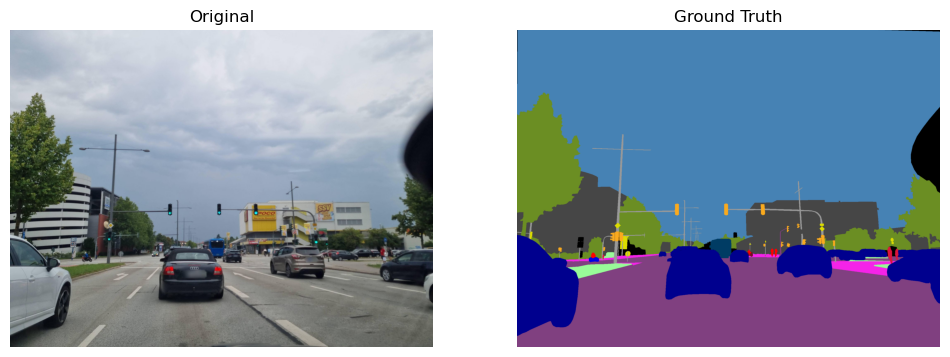

In [2]:
cvat_path = Path("./CVATAnnotations")
image_path = cvat_path / "bild1r.jpg"
label_path = cvat_path / "bild1.png"

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

rgb_label = cv2.imread(str(label_path))
rgb_label = cv2.cvtColor(rgb_label, cv2.COLOR_BGR2RGB)

plot_images(image, "Original", rgb_label, "Ground Truth")

## Segmentierung

Loaded model: deeplabv3plus
Best checkpoint:
 - Epoch: 199
 - Train Loss: 0.06996467659870784
 - Train Accuracy: 0.9596164226531982
 - Train MIoU: 0.6942357507803419
 - Val Loss: 0.15436224887768427
 - Val Accuracy: 0.9292846322059631
 - Val MIoU: 0.5089366528013779


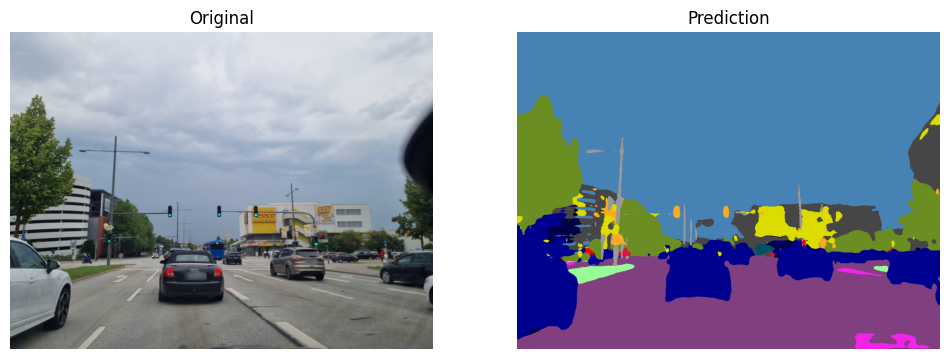

Results:
 - MIoU: 0.31546467327649297
 - Pixel Accuracy: 0.9140325784683228


In [16]:
model, device = load_model("deeplab", "deeplab_cityscapes_3258105")
prediction = infer(model, device, image)
miou, _, acc = eval(prediction, rgb_label, num_classes=20)

rgb_pred = label_to_color(prediction, CITYSCAPES_COLORS_20)
plot_images(image, "Original", rgb_pred, "Prediction")

print("Results:")
print(f" - MIoU: {miou}")
print(f" - Pixel Accuracy: {acc}")

Loaded model: segformer-b1
Best checkpoint:
 - Epoch: 252
 - Train Loss: 0.08738755968709787
 - Train Accuracy: 0.9332541863123576
 - Train MIoU: 0.5578513778173136
 - Val Loss: 0.13681321094433466
 - Val Accuracy: 0.9120073318481445
 - Val MIoU: 0.46682400445446676


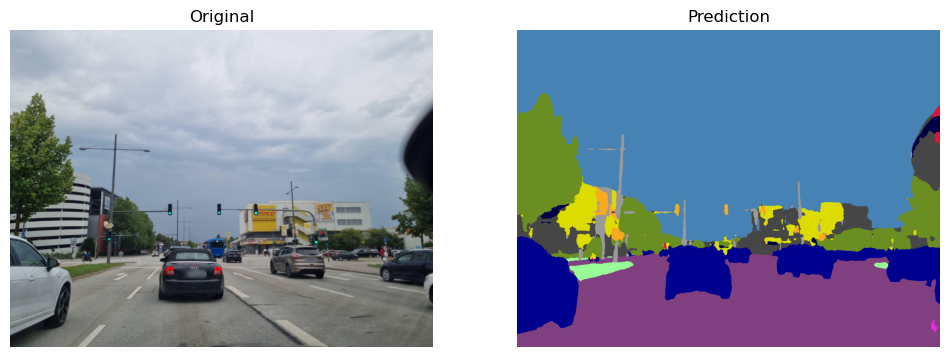

Results:
 - MIoU: 0.3233189583810059
 - Pixel Accuracy: 0.9248368144035339


In [3]:
model, device = load_model("segformer", "segfromer_3266966")
prediction = infer(model, device, image)
miou, _, acc = eval(prediction, rgb_label, num_classes=20)

rgb_pred = label_to_color(prediction, CITYSCAPES_COLORS_20)
plot_images(image, "Original", rgb_pred, "Prediction")

print("Results:")
print(f" - MIoU: {miou}")
print(f" - Pixel Accuracy: {acc}")

Loaded model: u-net
Best checkpoint:
 - Epoch: 234
 - Train Loss: 0.20631385147571563
 - Train Accuracy: 0.8818898439407349
 - Train MIoU: 0.34719124397876494
 - Val Loss: 0.23474901914596558
 - Val Accuracy: 0.8743003010749817
 - Val MIoU: 0.327700275788586


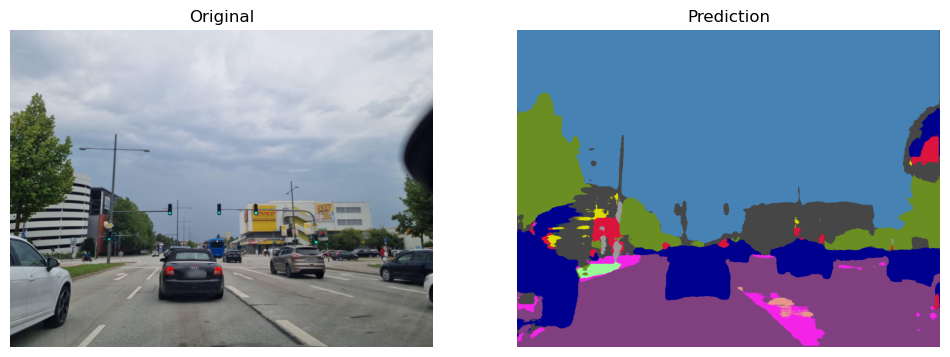

Results:
 - MIoU: 0.25757463878670817
 - Pixel Accuracy: 0.9085167646408081


In [4]:
model, device = load_model("unet", "unet_3267195")
prediction = infer(model, device, image)
miou, _, acc = eval(prediction, rgb_label, num_classes=20)

rgb_pred = label_to_color(prediction, CITYSCAPES_COLORS_20)
plot_images(image, "Original", rgb_pred, "Prediction")

print("Results:")
print(f" - MIoU: {miou}")
print(f" - Pixel Accuracy: {acc}")